[*********************100%***********************]  1 of 1 completed


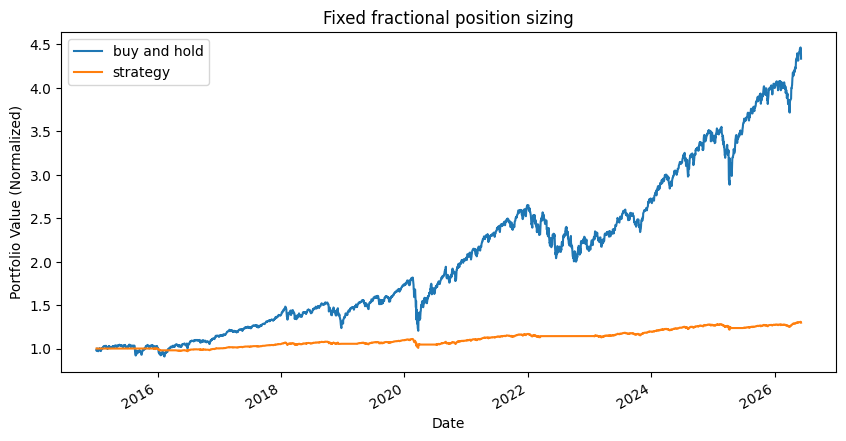

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Download data
df = yf.download("SPY", start="2015-01-01", auto_adjust=True)

if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.get_level_values(0)

# Moving averages
df["MA50"] = df["Close"].rolling(50).mean()
df["MA200"] = df["Close"].rolling(200).mean()

# Trading signal
df["signal"] = (df["MA50"] > df["MA200"]).astype(int)

# Daily returns
df["returns"] = df["Close"].pct_change()

# Fixed fractional sizing
fraction = 0.25

# Position held on the next day
df["position"] = fraction * df["signal"].shift(1)

# Strategy returns
df["strategy_returns"] = df["position"] * df["returns"]

# Equity curves
df["buy_and_hold"] = (1 + df["returns"]).cumprod()
df["strategy"] = (1 + df["strategy_returns"]).cumprod()

# Plot results
df["buy_and_hold"].plot(label='buy and hold', figsize=(10, 5))
df["strategy"].plot(label='strategy', figsize=(10, 5))
plt.legend()
plt.title("Fixed fractional position sizing")

plt.ylabel("Portfolio Value (Normalized)")
plt.show()

In [ ]:
# Buy-and-hold daily returns
buyhold_returns = df["returns"].dropna()

# Strategy daily returns
strategy_returns = df["strategy_returns"].dropna()

# Annualized Sharpe ratios (assuming risk-free rate = 0)
buyhold_sharpe = (
    buyhold_returns.mean()
    / buyhold_returns.std()
    * np.sqrt(252)
)

strategy_sharpe = (
    strategy_returns.mean()
    / strategy_returns.std()
    * np.sqrt(252)
)

print(f"Buy-and-Hold Sharpe Ratio: {buyhold_sharpe:.2f}")
print(f"Strategy Sharpe Ratio:     {strategy_sharpe:.2f}")

Buy-and-Hold Sharpe Ratio: 0.82
Strategy Sharpe Ratio:     0.65
